# 📘 Notebook 02: LeNet-5, the Network that Read Handwritten Digits

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Paper: LeCun, Bottou, Bengio and Haffner (1998)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab to train everything yourself.
>
> ⏱️ **Training time and limitations.** Each model trains for **5 epochs** on the 60,000 MNIST training images: about **1 minute** on an ordinary laptop processor for LeNet-5, and well under a minute on a Colab GPU (**Runtime → Change runtime type → GPU**). The paper trained for 20 epochs and added distorted copies of the digits, reaching an error of **0.95%** (0.8% with distortions); with 5 epochs and no distortions our numbers are slightly worse, and they vary by a few hundredths of a percent between runs. We also use modern conveniences that the 1998 network did not have: ReLU instead of a scaled tanh, max pooling instead of trainable average pooling, the Adam optimiser and a standard softmax output instead of the paper's radial basis function units. The **architecture**, its layer sizes and the idea behind it are those of the paper.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain why a fully connected network is a **poor fit for images**
- Explain the three ideas of a convolutional network: **local receptive fields**, **shared weights** and **pooling**
- Build LeNet-5 layer by layer and follow the **shape** of the data through it
- Train it on MNIST and compare it, fairly, with a fully connected network of a similar size
- Show that a convolutional network is robust to **shifts** that break a fully connected one
- Look inside a trained network: its **filters** and **feature maps**

> **Prerequisites:** [Notebook 01: the Perceptron and the MLP](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/01_perceptron_and_mlp.ipynb). PyTorch tensors and training loops are introduced in [From Python to Deep Learning and Fine-Tuning](https://giannis00.github.io/teaching/#deep-learning).
>
> 🔭 **Why this notebook matters:** in the 1990s, LeNet read millions of handwritten cheques a day in American banks. It was the first convolutional network that worked in industry, and every image model since, from AlexNet in 2012 to the networks in your phone camera, is its descendant. The three ideas you meet here are still the core of computer vision.

## 1. The paper

> 📄 Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, [*Gradient-based learning applied to document recognition*](https://doi.org/10.1109/5.726791), Proceedings of the IEEE 86(11), 1998. ([PDF](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf))

### Intuition first
A fully connected network treats an image as a list of 784 unrelated numbers. Move a digit two pixels to the right, and every input changes: the network sees a completely new pattern. It also needs a separate weight for every pixel in every unit, hundreds of thousands of weights to learn things like "a short vertical stroke" again and again at every position.

LeCun's answer has three ideas:
1. **Local receptive fields.** Each unit looks only at a small patch, 5 × 5 pixels, because strokes and corners are local.
2. **Shared weights.** The same small detector (a **filter**) slides over the whole image. A vertical-stroke detector is useful everywhere, so it is learned once. The output of one filter over the whole image is a **feature map**.
3. **Subsampling (pooling).** After detecting features, shrink the map, keeping only the strongest response in each small area. The exact position of a stroke matters less than its rough position, which makes the network tolerant to small shifts.

Stack these, and early layers find strokes, later layers combine strokes into parts of digits, and the last layers decide which digit it is.

In [1]:
import gzip
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "on", device)

PyTorch 2.2.2+cpu on cpu


## 2. The data: MNIST

60,000 training and 10,000 test images of handwritten digits, 28 × 28 pixels. The original site is no longer reliable, so we read the same files from a public mirror, in the IDX format of Notebook 08 of *From Questions to Answers*.

train (60000, 1, 28, 28)  test (10000, 1, 28, 28)


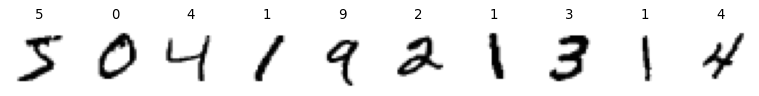

In [2]:
MIRROR = "https://ossci-datasets.s3.amazonaws.com/mnist/"

def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(MIRROR + name).read()), dtype=np.uint8, offset=header)

def as_tensor(images):
    return torch.tensor(images.reshape(-1, 1, 28, 28), dtype=torch.float32) / 255.0

X_train = as_tensor(read_idx("train-images-idx3-ubyte.gz", 16))
y_train = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = as_tensor(read_idx("t10k-images-idx3-ubyte.gz", 16))
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
print("train", tuple(X_train.shape), " test", tuple(X_test.shape))

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, i in zip(axes, range(10)):
    ax.imshow(X_train[i, 0], cmap="gray_r")
    ax.set_title(int(y_train[i]))
    ax.axis("off")
plt.show()

**What we see.** 60,000 training and 10,000 test images, each stored as *(1, 28, 28)*: one channel (greyscale), 28 rows, 28 columns. The ten examples show how much handwriting varies: the two 1s lean differently, the 4s are open and closed. This variety is what the network must learn to ignore.

## 3. The architecture, layer by layer

The paper's Figure 2 names the layers C1 to F6. In PyTorch:

| Layer | What it does | Output shape |
|---|---|---|
| C1 | 6 filters of 5 × 5 (the input is padded to 32 × 32, as in the paper) | 6 × 28 × 28 |
| S2 | pooling 2 × 2 | 6 × 14 × 14 |
| C3 | 16 filters of 5 × 5 | 16 × 10 × 10 |
| S4 | pooling 2 × 2 | 16 × 5 × 5 |
| C5 | fully connected to 120 units (a 5 × 5 convolution in the paper) | 120 |
| F6 | fully connected | 84 |
| Output | one score per digit | 10 |

In [3]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.c5 = nn.Linear(16 * 5 * 5, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)   # C1 + S2
        x = F.max_pool2d(F.relu(self.c3(x)), 2)   # C3 + S4
        x = torch.flatten(x, 1)
        x = F.relu(self.c5(x))
        x = F.relu(self.f6(x))
        return self.out(x)

lenet = LeNet5().to(device)
x = X_train[:1].to(device)
print("input            ", tuple(x.shape))
x = F.max_pool2d(F.relu(lenet.c1(x)), 2); print("after C1 and S2  ", tuple(x.shape))
x = F.max_pool2d(F.relu(lenet.c3(x)), 2); print("after C3 and S4  ", tuple(x.shape))
count = lambda m: sum(p.numel() for p in m.parameters())
print("trainable parameters:", f"{count(lenet):,}")

input             (1, 1, 28, 28)
after C1 and S2   (1, 6, 14, 14)
after C3 and S4   (1, 16, 5, 5)
trainable parameters: 61,706


**What we see.** The data shrinks as it flows: 28 × 28 becomes 6 maps of 14 × 14 after C1 and S2, then 16 maps of 5 × 5 after C3 and S4, which are flattened into 400 numbers for the classifier. The whole network has **61,706** weights. Of these, the two convolutional layers need only about 2,600: six 5 × 5 filters, then sixteen filters over six maps, shared across every position. Most weights sit in the fully connected layers at the end.

## 4. A fair opponent: a fully connected network

To see what the convolutional ideas buy, we compare LeNet with a plain **multilayer perceptron** (Notebook 01) of a similar size: 784 inputs, two hidden layers, 10 outputs.

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 100), nn.ReLU(), nn.Linear(100, 10))

    def forward(self, x):
        return self.net(x)

print("MLP parameters:", f"{count(MLP()):,}", "   LeNet-5 parameters:", f"{count(LeNet5()):,}")

MLP parameters: 89,610    LeNet-5 parameters: 61,706


**What we see.** The MLP has **89,610** weights, almost half as many again as LeNet-5's **61,706**. If the MLP wins, it is not for lack of capacity.

## 5. Training

In [5]:
def accuracy(model, X, y, batch=2000):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), batch):
            correct += (model(X[i:i + batch].to(device)).argmax(1).cpu() == y[i:i + batch]).sum().item()
    return correct / len(X)

def fit(model, epochs=5, batch=128, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch):
            idx = order[i:i + batch]
            opt.zero_grad()
            loss = F.cross_entropy(model(X_train[idx].to(device)), y_train[idx].to(device))
            loss.backward()
            opt.step()
        history.append(accuracy(model, X_test, y_test))
        print(f"  epoch {epoch + 1}: test accuracy {history[-1]:.4f}")
    print(f"  training time {time.time() - start:.0f} s")
    return history

torch.manual_seed(0)
print("MLP")
mlp = MLP().to(device)
mlp_history = fit(mlp)
torch.manual_seed(0)
print("LeNet-5")
lenet = LeNet5().to(device)
lenet_history = fit(lenet)

MLP


  epoch 1: test accuracy 0.9373


  epoch 2: test accuracy 0.9578


  epoch 3: test accuracy 0.9653


  epoch 4: test accuracy 0.9678


...

  epoch 1: test accuracy 0.9709


  epoch 2: test accuracy 0.9780


  epoch 3: test accuracy 0.9825


  epoch 4: test accuracy 0.9895


  epoch 5: test accuracy 0.9879
  training time 49 s


**What we see.** After five passes over the data:
- The **MLP** reaches **97.2%** on the test digits, in a few seconds.
- **LeNet-5** reaches **98.8%** (98.95% after epoch 4), in about a minute on this processor (the exact time printed above varies from run to run).

LeNet-5 makes about **2.5 times fewer mistakes** (121 against 281) with **fewer** weights. Convolutions cost more computation per weight, which is why training is slower on a processor; on a GPU the difference almost vanishes. The paper reports 99.05% after 20 epochs; our shorter run lands within about a quarter of a percentage point.

LeNet-5 misreads 121 of 10,000 test digits


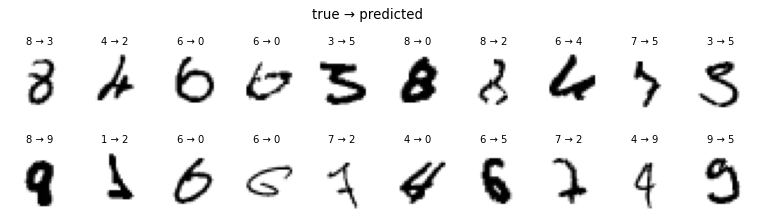

In [6]:
def errors(model):
    with torch.no_grad():
        pred = model(X_test.to(device)).argmax(1).cpu()
    return (pred != y_test).nonzero().ravel(), pred

wrong, pred = errors(lenet)
print(f"LeNet-5 misreads {len(wrong)} of 10,000 test digits")
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for ax, i in zip(axes.ravel(), wrong[:20]):
    ax.imshow(X_test[i, 0], cmap="gray_r")
    ax.set_title(f"{int(y_test[i])} → {int(pred[i])}", fontsize=9)
    ax.axis("off")
plt.suptitle("true → predicted", y=1.02)
plt.show()

**What we see.** LeNet-5 misreads **121** of 10,000 digits. Look at the errors: many are hard for a person too. A 6 whose loop is almost closed is read as 0, an 8 written with a thick blob as 3 or 9, a 7 with a crossbar as 2. A few are clear mistakes (a 4 read as 2). On MNIST, the remaining errors are a mixture of genuinely ambiguous handwriting and real failures, which is why progress beyond about 99.5% says more about the model than about reading digits.

## 6. The real test: move the digits

Pooling and shared weights should make the network tolerant to **shifts**. We move every test digit right and down by 1, 2 and 3 pixels, without retraining, and measure both networks at each step. (MNIST digits are about 20 pixels tall, so 3 pixels is already a large move.)

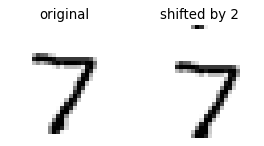

MLP        shift 0: 0.972   shift 1: 0.890   shift 2: 0.496   shift 3: 0.176


LeNet-5    shift 0: 0.988   shift 1: 0.969   shift 2: 0.811   shift 3: 0.416


In [7]:
shifted = torch.roll(X_test, shifts=(2, 2), dims=(2, 3))
fig, axes = plt.subplots(1, 2, figsize=(4, 2))
axes[0].imshow(X_test[0, 0], cmap="gray_r"); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(shifted[0, 0], cmap="gray_r"); axes[1].set_title("shifted by 2"); axes[1].axis("off")
plt.show()
for name, model in [("MLP", mlp), ("LeNet-5", lenet)]:
    row = [accuracy(model, torch.roll(X_test, shifts=(k, k), dims=(2, 3)), y_test) for k in range(4)]
    print(f"{name:8s}" + "".join(f"   shift {k}: {a:.3f}" for k, a in enumerate(row)))

**What we see.** On the original digits both networks are good. Then:
- A shift of **1 pixel** drops the MLP to **89.0%**, while LeNet-5 keeps **96.9%**.
- At **2 pixels**, the MLP collapses to **49.6%**, about a coin toss between two digits; LeNet-5 still reads **81.1%**.
- At **3 pixels** both fail (17.6% and 41.6%), but the MLP is close to random guessing (10%).

This is what the convolutional ideas buy: the same stroke detector works at every position, and pooling forgives small moves. It is **tolerance**, not immunity: LeNet-5 was trained on centred digits and has its limits too. (`torch.roll` wraps pixels from one edge to the other, which is harmless here because the borders of MNIST images are almost always blank; the small dash at the top of the shifted 7 is the bottom of its stroke.)

## 7. Inside the network

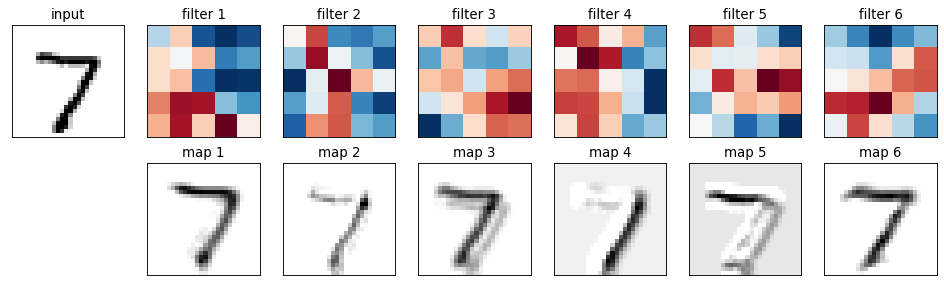

In [8]:
filters = lenet.c1.weight.detach().cpu()[:, 0]
with torch.no_grad():
    maps = F.relu(lenet.c1(X_test[:1].to(device))).cpu()[0]
fig, axes = plt.subplots(2, 7, figsize=(12, 3.6))
axes[0, 0].imshow(X_test[0, 0], cmap="gray_r"); axes[0, 0].set_title("input")
axes[1, 0].axis("off")
for k in range(6):
    axes[0, k + 1].imshow(filters[k], cmap="RdBu_r"); axes[0, k + 1].set_title(f"filter {k + 1}")
    axes[1, k + 1].imshow(maps[k], cmap="gray_r"); axes[1, k + 1].set_title(f"map {k + 1}")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

**What we see.** Top row: the six 5 × 5 filters of C1 after training (red positive, blue negative). Each is a small detector: several have a band of red next to a band of blue, the classic shape of an **edge detector** at a particular angle. Bottom row: what each filter finds in the digit 7. Map 2 lights up on the vertical stroke and part of the bar, map 5 responds to the edges on one side of the strokes, map 4 marks the background around the digit. Nobody programmed these detectors; they were learned from the examples, and they resemble the edge detectors that image processing used for decades and that neuroscientists found in the visual cortex.

## ⚠️ Common pitfalls

- **Forgetting the channel dimension.** Convolutions expect images as *(batch, channels, height, width)*; MNIST has one channel.
- **Getting the flatten size wrong.** The first linear layer must match the shape after the last pooling (here 16 × 5 × 5 = 400). Print the shapes, as in Section 3.
- **Comparing networks of very different sizes.** A fair comparison controls the number of parameters; LeNet wins here with fewer.
- **Testing only on data like the training data.** The shift test revealed a difference that the ordinary test set hid.
- **Expecting exactly the paper's numbers.** Different optimisers, epochs and random seeds move results by tenths of a percent; the ranking of the methods is what reproduces.

## ✏️ Exercises

### Exercise 1 (How much does pooling matter?)
Build a version of LeNet-5 **without** pooling: use `stride=2` in each convolution instead, so that the shapes stay the same. Train it for one epoch and compare it with LeNet-5 on the test set shifted by 2 pixels (`shifted`).

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
class StridedLeNet(LeNet5):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, kernel_size=5, padding=2, stride=2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.c5 = nn.Linear(16 * 5 * 5, 120)
    def forward(self, x):
        x = F.relu(self.c1(x))
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        return self.out(F.relu(self.f6(F.relu(self.c5(torch.flatten(x, 1))))))

torch.manual_seed(0)
strided = StridedLeNet().to(device)
fit(strided, epochs=1)
print("shifted:", accuracy(strided, shifted, y_test))
```

*Replacing the first pooling by a stride still reduces the size, and the network still learns well, but it typically loses some of the robustness to shifts. Pooling is a cheap, built-in tolerance to small movements.*
</details>

### Exercise 2 (Train on shifted digits)
Give the MLP a fair chance: train it for 5 epochs on training images that are randomly shifted by up to 3 pixels in each direction (`torch.roll` with a random amount per batch). Does it now handle the shifted test set?

In [10]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def fit_shifted(model, epochs=5, batch=128):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch):
            idx = order[i:i + batch]
            dx, dy = np.random.randint(-3, 4, size=2)
            xb = torch.roll(X_train[idx], shifts=(int(dx), int(dy)), dims=(2, 3))
            opt.zero_grad()
            F.cross_entropy(model(xb.to(device)), y_train[idx].to(device)).backward()
            opt.step()

torch.manual_seed(0)
mlp_aug = MLP().to(device)
fit_shifted(mlp_aug)
print("MLP trained on shifted digits: original", accuracy(mlp_aug, X_test, y_test), " shifted", accuracy(mlp_aug, shifted, y_test))
```

*Showing the MLP shifted examples (**data augmentation**) transforms its robustness: it now handles the shifted digits far better than the LeNet-5 we trained on unshifted images, at the cost of a little accuracy on the original ones. Architecture gives some tolerance for free, but it is not a substitute for training on the variation you expect; the best modern image models use both, convolutions **and** heavy augmentation, which is exactly what AlexNet did in Notebook 03.*
</details>

### Exercise 3 (Look at the second layer)
Plot the 16 feature maps of layer C3 for one test digit. Are they easier or harder to interpret than those of C1?

In [11]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
with torch.no_grad():
    h = F.max_pool2d(F.relu(lenet.c1(X_test[:1].to(device))), 2)
    c3 = F.relu(lenet.c3(h)).cpu()[0]
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(c3[k], cmap="gray_r")
    ax.axis("off")
plt.show()
```

*The C3 maps are only 10 × 10 and look like abstract blobs: each combines several C1 maps, so it responds to combinations of strokes rather than single edges. Deeper layers are harder for people to read, which is a general and still open problem of interpreting neural networks.*
</details>

## 🔑 Key takeaways

- Fully connected networks ignore the structure of images and need a weight for every pixel.
- **Convolutions** look at small patches and **share** the same filter across the image; **pooling** keeps the rough position of a feature and throws away the exact one.
- LeNet-5 beats an MLP of similar size with **fewer parameters**, and keeps working when the digits move.
- Early filters detect **strokes and edges**; later layers combine them into more abstract patterns.
- The ideas of 1998 are still the core of computer vision; what changed next was **scale**, the subject of Notebook 03.

---
**Next:** *Notebook 03: AlexNet and VGG*, where the same ideas, made much deeper and trained on a million photographs with GPUs, started the deep learning revolution of 2012.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*